# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos

---

### 1.1. Importar librerias, carga de archivos y guardar los df


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import levene
from scipy.stats import stats
from  scipy.stats import ttest_ind
from scipy.stats import chi2_contingency

In [2]:
# cargar archivos y guardar en orders, catalog y marketing
orders = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv")
catalog = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv")
marketing = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv") # tu código aquí

### Análisis de los df


In [3]:
def revisar_datos(df, nombre="DataFrame"):
    """
    Genera un resumen de calidad de datos para un DataFrame.
    """
    print(f"{'='*50}")
    print(f"REVISIÓN: {nombre}")
    print(f"{'='*50}")

    #visialización de 5 filas iniciales
    print("\n--- Primeras 5 filas ---")
    display(df.head())

    # Dimensiones
    print(f"\nDimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")

    # Tipos de datos
    print("\n--- Tipos de datos ---")
    print(df.dtypes)

    # Valores nulos
    nulos = df.isnull().sum()
    nulos_pct = (nulos / len(df) * 100).round(2)
    tabla_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje_%': nulos_pct})
    tabla_nulos = tabla_nulos[tabla_nulos['nulos'] > 0]
    if not tabla_nulos.empty:
        print("\n--- Valores nulos ---")
        print(tabla_nulos)
    else:
        print("\n--- Valores nulos ---\nNo hay valores nulos.")

    # Duplicados
    duplicados = df.duplicated().sum()
    print(f"\n--- Filas duplicadas ---\n{duplicados}")

    # Valores únicos por columna
    print("\n--- Valores únicos por columna ---")
    print(df.nunique())

    # Estadísticas descriptivas (numéricas)
    print("\n--- Estadísticas descriptivas (numéricas) ---")
    display(df.describe())

    # Estadísticas descriptivas (categóricas)
    cat_cols = df.select_dtypes(include=['object']).columns
    if len(cat_cols) > 0:
        print("\n--- Valores más frecuentes (categóricas) ---")
        for col in cat_cols:
            print(f"\n{col}:")
            print(df[col].value_counts().head(5))

    print(f"\n{'='*50}\n")


# Uso con tus tres datasets
revisar_datos(orders, "orders")
revisar_datos(catalog, "catalog")
revisar_datos(marketing, "marketing")



REVISIÓN: orders

--- Primeras 5 filas ---


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28



Dimensiones: 25100 filas x 12 columnas

--- Tipos de datos ---
id_pedido              object
id_usuario             object
fecha_hora_pedido      object
pais                   object
dispositivo            object
fuente_referencia      object
nombre_producto        object
categoria_producto     object
cantidad              float64
precio_unitario       float64
monto_descuento       float64
monto_total           float64
dtype: object

--- Valores nulos ---
                    nulos  porcentaje_%
pais                  300          1.20
dispositivo            20          0.08
fuente_referencia      30          0.12
nombre_producto        30          0.12
categoria_producto     80          0.32
cantidad               50          0.20
precio_unitario        50          0.20
monto_descuento        50          0.20

--- Filas duplicadas ---
100

--- Valores únicos por columna ---
id_pedido             25000
id_usuario             7642
fecha_hora_pedido       181
pais                      6
d

,cantidad,precio_unitario,monto_descuento,monto_total
count,25050.000000,25050.000000,25050.000000,2.510000e+04
mean,7.092735,259.305549,4.500798,2.072680e+03
std,296.277003,138.726461,5.223010,9.894995e+04
min,-2.000000,20.030000,0.000000,-4.926500e+02
25%,1.000000,138.377500,0.000000,1.805075e+02
50%,2.000000,258.715000,0.000000,3.417500e+02
75%,2.000000,380.332500,10.000000,5.185800e+02
max,20000.000000,499.960000,15.000000,8.840200e+06



--- Valores más frecuentes (categóricas) ---

id_pedido:
order_14695    2
order_4326     2
order_5951     2
order_14562    2
order_16515    2
Name: id_pedido, dtype: int64

id_usuario:
user_7769    11
user_5747    10
user_4065    10
user_3049    10
user_5748    10
Name: id_usuario, dtype: int64

fecha_hora_pedido:
2025-06-25    176
2025-04-17    169
2025-06-12    164
2025-05-06    162
2025-02-27    162
Name: fecha_hora_pedido, dtype: int64

pais:
Colombia     7520
Mexico       7502
Argentina    7291
mexico        865
colombia      823
Name: pais, dtype: int64

dispositivo:
desktop    12759
mobile     12321
Name: dispositivo, dtype: int64

fuente_referencia:
social         8428
organic        8329
paid_search    8313
Name: fuente_referencia, dtype: int64

nombre_producto:
Vacuum-Pro-Black      4199
Blender-XL-Red        4195
Jacket-Winter-M       4192
Sneakers-Urban-42     4160
Laptop-Gaming-16GB    2794
Name: nombre_producto, dtype: int64

categoria_producto:
Hogar          8385
Moda 

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


... (3 outputs left out)

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40



Dimensiones: 1620 filas x 5 columnas

--- Tipos de datos ---
fecha          object
pais           object
id_campaña     object
canal          object
gasto         float64
dtype: object

--- Valores nulos ---
       nulos  porcentaje_%
canal    101          6.23

--- Filas duplicadas ---
0

--- Valores únicos por columna ---
fecha          180
pais             3
id_campaña       9
canal            3
gasto         1612
dtype: int64

--- Estadísticas descriptivas (numéricas) ---


,gasto
count,1620.00000
mean,1772.74292
std,734.43294
min,501.11000
25%,1128.03000
50%,1782.42500
75%,2420.68500
max,2999.36000



--- Valores más frecuentes (categóricas) ---

fecha:
2025-06-27    9
2025-03-08    9
2025-01-16    9
2025-05-21    9
2025-05-27    9
Name: fecha, dtype: int64

pais:
Mexico       540
Colombia     540
Argentina    540
Name: pais, dtype: int64

id_campaña:
social_Colombia          180
paid_search_Argentina    180
social_Mexico            180
organic_Colombia         180
organic_Argentina        180
Name: id_campaña, dtype: int64

canal:
paid_search    507
organic        506
social         506
Name: canal, dtype: int64




**NOTA:
Observaciones de los df**

1. df_Orders

- Hay 25100 filas y 12 columnas
- Hay valores nulos en 8 columnas (entre 0.1 y 1.2%) ---> Revisar y definir que hacer
- Columna "Fecha_hora_pedido" está en dtype objetc ---> cambiar
- Hay 100 filas duplicadas ---> Revisar y definir que hacer
- Hay valores centinels en columnas "cantidad" y "monto_total" ---> Revisar y definir que hacer
- Hay valores outliers en columna "cantidad" ---> Revisar y definir que hacer
- En la columna "pais" hay escritura no estandarizada ---> Estandarizar escritura

2. df_Catalog
- Hay 7 filas y 4 columnas
- Datos de columnas Ok

3. df_Marketing
- Hay 1620 filas y 5 columnas
- Columna "Fecha" está en dtype objetc ---> cambiar
- Hay valores nulos en la columna "canal"(6.23%)-->Revisar y definir que hacer

### 1.3. Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

---

#### Limpieza a df ORDERS

- **FILAS DUPLICADAS**

In [4]:
#Creación de copia orders_limpio para resto de análisis
orders_limpio=orders.copy()

In [5]:
filas_duplicadas = orders_limpio[orders_limpio.duplicated(subset=["id_pedido"], keep=False)]
display(filas_duplicadas.sort_values("id_pedido"))

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
25023,order_10082,user_690,2025-02-17,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67
10082,order_10082,user_690,2025-02-17,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67
25037,order_10709,user_6783,2025-02-16,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10
10709,order_10709,user_6783,2025-02-16,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10
25065,order_10829,user_7697,2025-01-23,Argentina,mobile,social,Phone-Pro-128GB,Electronica,2.0,115.54,0.0,231.08
...,...,...,...,...,...,...,...,...,...,...,...,...
25048,order_8326,user_6177,2025-06-14,Argentina,mobile,organic,Vacuum-Pro-Black,Hogar,1.0,457.53,0.0,457.53
25043,order_8414,user_4073,2025-05-10,Colombia,mobile,social,Jacket-Winter-M,Moda,2.0,144.35,10.0,278.71
8414,order_8414,user_4073,2025-05-10,Colombia,mobile,social,Jacket-Winter-M,Moda,2.0,144.35,10.0,278.71
25056,order_974,user_3262,2025-05-04,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16


In [6]:

# Eliminación de Filas duplicadas y creación del Df limpio "orders_limpio"
orders_limpio = orders_limpio.drop_duplicates( )


In [7]:
orders_limpio.duplicated().sum()

0

**Observación**

Las filas duplicadas tiene los mismos datos en cada una de las columnas, por tanto se estima conveniente eliminar las columnas **que tengan datos exactamente iguales en todas las columnas**

**Resultado de limpieza de outliers "cantidad"=** Se eliminan 100 filas del df orders_limpio

- **DATOS NO VÁLIDOS Y OUTLIERS**

In [8]:
#Análisis de DATOS OUTLIERS en columna cantidad

orders_limpio[orders_limpio["cantidad"]>=10000]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
3521,order_3521,user_5812,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,43.14,0.0,431400.0
3522,order_3522,user_3575,2025-03-29,Argentina,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,280.55,0.0,2805500.0
3586,order_3586,user_3380,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,490.35,0.0,4903500.0
3643,order_3643,user_4440,2025-01-07,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,238.15,0.0,2381500.0
3656,order_3656,user_884,2025-01-01,Argentina,mobile,organic,Laptop-Gaming-16GB,Electronica,20000.0,297.66,0.0,5953200.0
3668,order_3668,user_7270,2025-06-24,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,348.31,0.0,6966200.0
3689,order_3689,user_6566,2025-06-16,mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,87.69,0.0,876900.0
3722,order_3722,user_4723,2025-05-09,Argentina,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,442.01,0.0,8840200.0
3726,order_3726,user_2536,2025-02-12,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,20000.0,290.85,0.0,5817000.0
3748,order_3748,user_7096,2025-02-23,Mexico,desktop,organic,Laptop-Gaming-16GB,Electronica,10000.0,336.93,0.0,3369300.0


In [9]:
otro= orders_limpio[orders_limpio["cantidad"]>= 10000]
orders_limpio=orders_limpio[orders_limpio["cantidad"]< 10000]

**Observación**

Teiendo en cuenta que no se tiene al momento, mayor información relacionada con las cantidades de compras, se decide dejar el df orders_limpio solo con los datos en donde la columna cantidad tiene valores menores de 10000. 

**Resultado de limpieza de outliers "cantidad"=** Se eliminan 10 filas del df orders_limpio

In [10]:
#Análisis de DATOS NO VÁLIDOS  en columnas cantidad y monto total

orders_limpio['cantidad'].le(0).sum()
orders_limpio['monto_total'].le(0).sum()

4

In [11]:
#Reemplazo de valores no válidos por nan
orders_limpio.loc[orders_limpio['cantidad'] <= 0, 'cantidad'] = np.nan


In [12]:
orders_limpio.loc[orders_limpio['monto_total'] <= 0, 'monto_total'] = np.nan

In [13]:
orders_limpio.isnull().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     30
cantidad                4
precio_unitario         0
monto_descuento         0
monto_total             4
dtype: int64



**Observación**

Se observan 10 filas con datos outliers sospechosos en la columna cantidad (valores de 10000 y 20000), y valores no válidos en columnas cantidad y monto_total. Estos últimos se reemplazan por Nan.

Se decide imputar datos con moda

- **DATOS NULOS** 

In [14]:
#Revisión de datos nulos en país

orders_limpio["pais"].isna().sum()

300

In [15]:
orders_limpio[orders_limpio["pais"].isna()]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
124,order_124,user_6671,2025-04-12,NaN,mobile,organic,Blender-XL-Red,Hogar,1.0,298.44,5.0,293.44
125,order_125,user_5263,2025-05-30,NaN,mobile,organic,Tablet-Standard-64GB,Electronica,1.0,133.13,0.0,133.13
126,order_126,user_4952,2025-04-19,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,2.0,177.23,0.0,354.45
127,order_127,user_2619,2025-06-26,NaN,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,329.53,10.0,319.53
128,order_128,user_2444,2025-05-06,NaN,desktop,social,Vacuum-Pro-Black,Hogar,2.0,218.43,0.0,436.86
...,...,...,...,...,...,...,...,...,...,...,...,...
419,order_419,user_3429,2025-04-06,NaN,mobile,social,Jacket-Winter-M,Moda,1.0,172.07,0.0,172.07
420,order_420,user_2674,2025-01-22,NaN,desktop,organic,Phone-Pro-128GB,Electronica,2.0,369.70,0.0,739.39
421,order_421,user_2248,2025-01-22,NaN,mobile,organic,Jacket-Winter-M,Moda,2.0,209.25,0.0,418.50
422,order_422,user_5872,2025-05-13,NaN,mobile,organic,Sneakers-Urban-42,Moda,2.0,350.87,10.0,691.73


**Observación**
Teniendo en cuenta que de acuerdo a lo primeros análisis el porcentaje de datos nulos en la columna "país" corresponde a un 1.20% (muy bajo), se decide imputar datos


- **IMPUTACIÓN DE DATOS NULOS Y NaN**

Las columnas categóricas se imputan con la moda y la columnas numéricas con la mediana


In [16]:
col_cat =["pais","dispositivo","fuente_referencia","nombre_producto","categoria_producto"]

In [17]:
col_num =["cantidad","precio_unitario", "monto_descuento","monto_total"]

In [18]:
def imputar_datos_moda (df,col):
    moda_valor = df[col].mode()[0]
    df[col] = df[col].fillna(moda_valor)
    

    return df
    

for col in col_cat:
    orders_limpio = imputar_datos_moda(orders_limpio, col)


In [19]:
def imputar_datos_med (df,col):
    med_valor = df[col].median()
    df[col] = df[col].fillna(med_valor)
    
    return df
    
for col in col_num:
    orders_limpio = imputar_datos_med(orders_limpio, col)

In [20]:
orders_limpio.isnull().sum()

id_pedido             0
id_usuario            0
fecha_hora_pedido     0
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
cantidad              0
precio_unitario       0
monto_descuento       0
monto_total           0
dtype: int64

- **FORMATO FECHA**

In [21]:
#Cambio de formato de columna fecha_hora_pedido

def formato_fecha(df, col):
    df[col] = pd.to_datetime(
        df[col],
        dayfirst=True,
        errors="raise"
    ).dt.date

formato_fecha(orders_limpio, "fecha_hora_pedido")

- **ESTANDARIZACIÓN DE NOMBRES**

In [22]:
#Estandarización de escritura en la columna pais
orders_limpio["pais"] = orders_limpio["pais"].str.strip().str.title()

In [23]:
orders_limpio["pais"].nunique()

3

In [24]:
orders_limpio["cantidad"]=orders_limpio["cantidad"].astype(int)

-**ESTANDARIZACIÓN EN TIPO DE DATO NUMERICO DE MONTOS**

In [25]:


def formato_montos (df,col):
    df[col]=pd.to_numeric(df[col], errors="coerce")
    df[col]=df[col].astype(float).round(3)

formato_montos(orders_limpio,"precio_unitario")



In [26]:

formato_montos(orders_limpio,"monto_total")

- **CONFIRMACIÓN DE LIMPIEZA DE ORDERS_LIMPIO**

In [27]:
revisar_datos(orders_limpio, "orders")

REVISIÓN: orders

--- Primeras 5 filas ---


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.0,336.28



Dimensiones: 24940 filas x 12 columnas

--- Tipos de datos ---
id_pedido              object
id_usuario             object
fecha_hora_pedido      object
pais                   object
dispositivo            object
fuente_referencia      object
nombre_producto        object
categoria_producto     object
cantidad                int64
precio_unitario       float64
monto_descuento       float64
monto_total           float64
dtype: object

--- Valores nulos ---
No hay valores nulos.

--- Filas duplicadas ---
0

--- Valores únicos por columna ---
id_pedido             24940
id_usuario             7640
fecha_hora_pedido       181
pais                      3
dispositivo               2
fuente_referencia         3
nombre_producto           7
categoria_producto        3
cantidad                  2
precio_unitario       19535
monto_descuento           4
monto_total           21484
dtype: int64

--- Estadísticas descriptivas (numéricas) ---


,cantidad,precio_unitario,monto_descuento,monto_total
count,24940.000000,24940.000000,24940.000000,24940.000000
mean,1.505012,259.364026,4.504411,385.871982
std,0.499985,138.692491,5.224325,255.669227
min,1.000000,20.030000,0.000000,5.240000
25%,1.000000,138.455000,0.000000,180.630000
50%,2.000000,258.775000,0.000000,341.415000
75%,2.000000,380.397500,10.000000,517.630000
max,2.000000,499.960000,15.000000,999.890000



--- Valores más frecuentes (categóricas) ---

id_pedido:
order_17253    1
order_17287    1
order_20751    1
order_8830     1
order_9191     1
Name: id_pedido, dtype: int64

id_usuario:
user_7769    11
user_4065    10
user_6272    10
user_5111    10
user_1554    10
Name: id_usuario, dtype: int64

fecha_hora_pedido:
2025-06-25    175
2025-04-17    167
2025-02-27    162
2025-06-12    161
2025-05-06    161
Name: fecha_hora_pedido, dtype: int64

pais:
Colombia     8587
Mexico       8322
Argentina    8031
Name: pais, dtype: int64

dispositivo:
desktop    12700
mobile     12240
Name: dispositivo, dtype: int64

fuente_referencia:
social         8413
organic        8268
paid_search    8259
Name: fuente_referencia, dtype: int64

nombre_producto:
Blender-XL-Red        4206
Vacuum-Pro-Black      4170
Jacket-Winter-M       4166
Sneakers-Urban-42     4129
Laptop-Gaming-16GB    2768
Name: nombre_producto, dtype: int64

categoria_producto:
Hogar          8376
Moda           8295
Electronica    8269
N

### Limpieza de MARKETING

- **FORMATO FECHA**

In [28]:
formato_fecha (marketing,"fecha")

- **DATOS NULOS**

In [29]:
#Análisis de distribución de nulos de acuerdo al país

marketing[marketing["canal"].isna()].groupby("pais").size()

pais
Argentina    34
Colombia     33
Mexico       34
dtype: int64

In [30]:
marketing_limpio = marketing.copy()

In [31]:
marketing_limpio = imputar_datos_moda(marketing_limpio, "canal")


**Observación**

Los datos se imputan con la moda

In [32]:
marketing_limpio.isna().sum()

fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64

-**ESTANDARIZACIÓN EN FORMATO DE MONTOS**

In [33]:
formato_montos(marketing_limpio,"gasto")


- **CONFIRMACIÓN DE LIMPIEZA DE MARKETING_LIMPIO**

In [34]:

revisar_datos(marketing_limpio, "marketing")

REVISIÓN: marketing

--- Primeras 5 filas ---


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40



Dimensiones: 1620 filas x 5 columnas

--- Tipos de datos ---
fecha          object
pais           object
id_campaña     object
canal          object
gasto         float64
dtype: object

--- Valores nulos ---
No hay valores nulos.

--- Filas duplicadas ---
0

--- Valores únicos por columna ---
fecha          180
pais             3
id_campaña       9
canal            3
gasto         1612
dtype: int64

--- Estadísticas descriptivas (numéricas) ---


,gasto
count,1620.00000
mean,1772.74292
std,734.43294
min,501.11000
25%,1128.03000
50%,1782.42500
75%,2420.68500
max,2999.36000



--- Valores más frecuentes (categóricas) ---

fecha:
2025-02-27    9
2025-05-08    9
2025-04-17    9
2025-01-04    9
2025-01-18    9
Name: fecha, dtype: int64

pais:
Mexico       540
Colombia     540
Argentina    540
Name: pais, dtype: int64

id_campaña:
social_Colombia          180
paid_search_Argentina    180
social_Mexico            180
organic_Colombia         180
organic_Argentina        180
Name: id_campaña, dtype: int64

canal:
paid_search    608
organic        506
social         506
Name: canal, dtype: int64




---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [35]:
# exportar datasets


orders_limpio.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing_limpio.to_csv('marketing_clean.csv', index=False)


---


## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 


**📊 Parte 1: Rentabilidad del negocio**

a. Calculo **ingreso_total**

In [36]:
ingreso_total = orders_limpio["monto_total"].sum()
print(f'Ingreso total (Revenue): {orders_limpio["monto_total"].sum():,.2f}')

Ingreso total (Revenue): 9,623,647.22


In [37]:
orders_limpio[orders_limpio["id_pedido"].isin(["order_266","order_267","order_268","order_269"])]["monto_total"].sum()

1365.66

b. Calculo **costo_total**

**Observación**

Para análisis el costo total se realiza los siguiente:
1. Se realiza unión tipo left, de los df orders_limpio y catalog, utilizando como llave "nombre_producto"
2. Sea analiza el df creado
4. Se calcula el costo total


1. Unión de dataset orders_limpio y catalog, usanto unión **left**

In [38]:
orders_vs_catalog = orders_limpio.merge(catalog,on=["nombre_producto"], how="left")


In [39]:
orders_vs_catalog

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto_x,cantidad,precio_unitario,monto_descuento,monto_total,categoria_producto_y,costo_unitario,proveedor
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.0,665.37,Moda,189.31,Mcmillan-Rhodes
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1,176.86,5.0,171.86,Electrónica,25.21,Bowers LLC
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.0,195.99,Hogar,176.64,Long-Reid
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1,257.87,15.0,242.87,Electrónica,25.21,Bowers LLC
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.0,336.28,Hogar,176.64,Long-Reid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24935,order_24995,user_4217,2025-04-16,Argentina,mobile,social,Tablet-Standard-64GB,Electronica,1,64.57,0.0,64.57,Electrónica,25.21,Bowers LLC
24936,order_24996,user_3945,2025-02-14,Argentina,mobile,social,Vacuum-Pro-Black,Hogar,2,292.90,15.0,570.81,Hogar,16.60,"Rivera, Carr and Finley"
24937,order_24997,user_3119,2025-03-27,Colombia,mobile,social,Jacket-Winter-M,Moda,1,226.85,0.0,226.85,Moda,189.31,Mcmillan-Rhodes
24938,order_24998,user_7218,2025-02-01,Mexico,mobile,social,Sneakers-Urban-42,Moda,2,418.06,0.0,836.12,Moda,17.21,Greene-Smith


In [40]:
orders_vs_catalog.isna().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                    0
dispositivo             0
fuente_referencia       0
nombre_producto         0
categoria_producto_x    0
cantidad                0
precio_unitario         0
monto_descuento         0
monto_total             0
categoria_producto_y    0
costo_unitario          0
proveedor               0
dtype: int64

In [41]:
orders_vs_catalog.describe()

,cantidad,precio_unitario,monto_descuento,monto_total,costo_unitario
count,24940.000000,24940.000000,24940.000000,24940.000000,24940.000000
mean,1.505012,259.364026,4.504411,385.871982,102.092883
std,0.499985,138.692491,5.224325,255.669227,98.723465
min,1.000000,20.030000,0.000000,5.240000,10.120000
25%,1.000000,138.455000,0.000000,180.630000,16.600000
50%,2.000000,258.775000,0.000000,341.415000,25.210000
75%,2.000000,380.397500,10.000000,517.630000,189.310000
max,2.000000,499.960000,15.000000,999.890000,280.680000


In [42]:
orders_vs_catalog.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 24940 entries, 0 to 24939
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_pedido             24940 non-null  object 
 1   id_usuario            24940 non-null  object 
 2   fecha_hora_pedido     24940 non-null  object 
 3   pais                  24940 non-null  object 
 4   dispositivo           24940 non-null  object 
 5   fuente_referencia     24940 non-null  object 
 6   nombre_producto       24940 non-null  object 
 7   categoria_producto_x  24940 non-null  object 
 8   cantidad              24940 non-null  int64  
 9   precio_unitario       24940 non-null  float64
 10  monto_descuento       24940 non-null  float64
 11  monto_total           24940 non-null  float64
 12  categoria_producto_y  24940 non-null  object 
 13  costo_unitario        24940 non-null  float64
 14  proveedor             24940 non-null  object 
dtypes: float64(4), int6

3. Se crea la columna "margen"

In [43]:
orders_vs_catalog["margen"]= orders_vs_catalog["monto_total"] -orders_vs_catalog["cantidad"] * orders_vs_catalog["costo_unitario"]

In [44]:
orders_vs_catalog

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto_x,cantidad,precio_unitario,monto_descuento,monto_total,categoria_producto_y,costo_unitario,proveedor,margen
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.0,665.37,Moda,189.31,Mcmillan-Rhodes,286.75
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1,176.86,5.0,171.86,Electrónica,25.21,Bowers LLC,146.65
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.0,195.99,Hogar,176.64,Long-Reid,-157.29
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1,257.87,15.0,242.87,Electrónica,25.21,Bowers LLC,217.66
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.0,336.28,Hogar,176.64,Long-Reid,159.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24935,order_24995,user_4217,2025-04-16,Argentina,mobile,social,Tablet-Standard-64GB,Electronica,1,64.57,0.0,64.57,Electrónica,25.21,Bowers LLC,39.36
24936,order_24996,user_3945,2025-02-14,Argentina,mobile,social,Vacuum-Pro-Black,Hogar,2,292.90,15.0,570.81,Hogar,16.60,"Rivera, Carr and Finley",537.61
24937,order_24997,user_3119,2025-03-27,Colombia,mobile,social,Jacket-Winter-M,Moda,1,226.85,0.0,226.85,Moda,189.31,Mcmillan-Rhodes,37.54
24938,order_24998,user_7218,2025-02-01,Mexico,mobile,social,Sneakers-Urban-42,Moda,2,418.06,0.0,836.12,Moda,17.21,Greene-Smith,801.70


3. Se calcula el costo total

In [45]:
costo_total = (orders_vs_catalog["costo_unitario"]*orders_vs_catalog["cantidad"]).sum()
print(f'Costo total: {(orders_vs_catalog["costo_unitario"]*orders_vs_catalog["cantidad"]).sum():,.2f}')

Costo total: 3,836,898.77


c. Calculo **Inversión de Marketing**

Para análisis de la inversión total de marketing se realiza los siguiente:
    
1. Se crea un df - ventas_diarias- a partir de las columnas "fecha", "país", "canal" y "monto_ total" del df orders_limpio , y las columnas "id_campaña" y "gasto" del df marketing_limpio
2. Se realiza unión tipo left entre los df  ventas_diarias y marketing
3. Se analiza el df creado
4. Se calcula la inversión general

1. Creación de df ventas_diarias y unión de los df

In [46]:
ventas_diarias = orders_limpio.groupby(["fecha_hora_pedido", "pais", "fuente_referencia"])["monto_total"].sum().reset_index()
ventas_diarias = ventas_diarias.rename(columns={"fuente_referencia": "canal", "fecha_hora_pedido": "fecha"})

ventas_vs_marketing = ventas_diarias.merge(marketing_limpio, on=["fecha", "pais", "canal"], how="left")

In [47]:
ventas_vs_marketing

,fecha,pais,canal,monto_total,id_campaña,gasto
0,2025-01-01,Argentina,organic,7499.05,organic_Argentina,1365.62
1,2025-01-01,Argentina,paid_search,4160.15,paid_search_Argentina,1282.65
2,2025-01-01,Argentina,social,3603.30,social_Argentina,1534.69
3,2025-01-01,Colombia,organic,7110.93,organic_Colombia,2597.21
4,2025-01-01,Colombia,paid_search,9047.47,paid_search_Colombia,1771.40
...,...,...,...,...,...,...
1692,2025-06-30,Colombia,paid_search,3661.82,NaN,NaN
1693,2025-06-30,Colombia,social,6852.21,NaN,NaN
1694,2025-06-30,Mexico,organic,4022.38,NaN,NaN
1695,2025-06-30,Mexico,paid_search,4284.25,NaN,NaN


**Observación**

Las columnas con datos Nan es válida, asumiendo los datos NaN como montos de compras en las cuales no se utilizó estrategia de marketing

2. Se analiza el df creado

In [48]:
ventas_vs_marketing.isna().sum()

fecha           0
pais            0
canal           0
monto_total     0
id_campaña     77
gasto          77
dtype: int64

3. Se calcula el gasto de marketing

In [49]:

gasto_marketing = ventas_vs_marketing["gasto"].sum()
print(f'Gasto marketing: {ventas_vs_marketing["gasto"].sum():,.2f}')


Gasto marketing: 2,871,843.53


d. Calculo **profit**

In [50]:
profit = ingreso_total - costo_total - gasto_marketing

In [51]:
print(f'Rentabilidad (profit): {profit:,.2f}')

Rentabilidad (profit): 2,914,904.92


**VISUALIZACION KPI´s: RENTABILIDAD DEL NEGOCIO**

In [52]:
categorias = ["Ingreso Total", "Costo Total","Gasto Marketing","Rentabilidad"]

In [53]:
valores = [ingreso_total, costo_total, gasto_marketing, profit ]

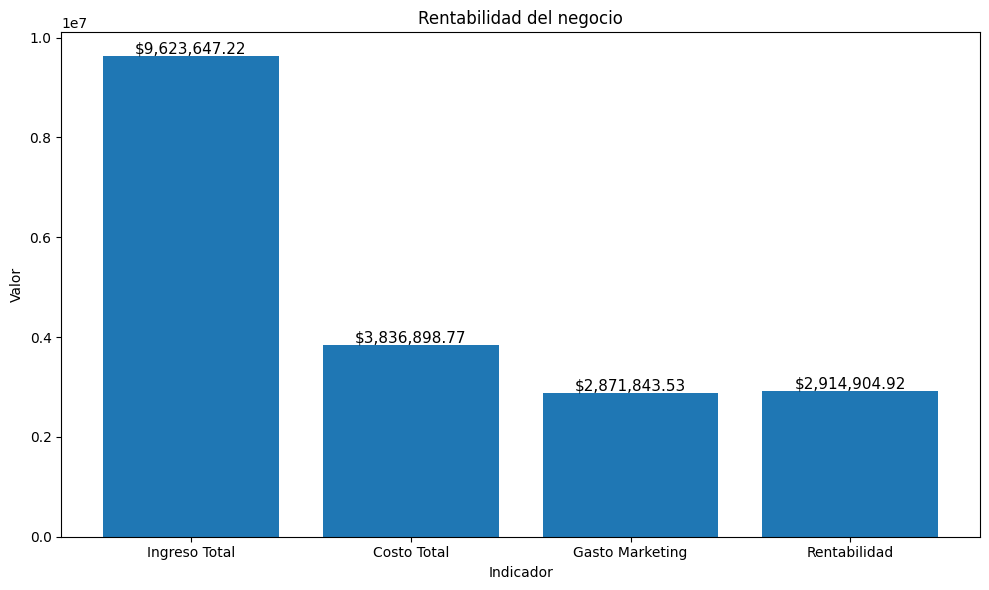

In [54]:
plt.figure(figsize=(10, 6))
barras = plt.bar(categorias, valores)


plt.title("Rentabilidad del negocio")
plt.ylabel("Valor")
plt.xlabel("Indicador")

# Mostrar el valor encima de cada barra
for barra, valor in zip(barras, valores):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"${valor:,.2f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()


**📈 Parte 2: Comportamiento de ventas**

a. Calculo ***Tiquet promedio**

In [55]:

prom_ticket = ventas_vs_marketing["monto_total"].mean()
print(f'Ticket promedio: {ventas_vs_marketing["monto_total"].mean():,.2f}')



Ticket promedio: 5,910.44


b. Calculo **Cantidad promedio de productos por orden**

In [56]:
cant_prom_producto_orden = orders_limpio["cantidad"].mean()
print(f'Cantidad promedio de productos por orden: {orders_limpio["cantidad"].mean():,.0f}')


Cantidad promedio de productos por orden: 2


c. Calculo **Producto mas vendido**

In [57]:
orders_limpio.groupby("nombre_producto")["cantidad"].sum().sort_values(ascending=False)


nombre_producto
Blender-XL-Red          6324
Vacuum-Pro-Black        6284
Jacket-Winter-M         6256
Sneakers-Urban-42       6172
Laptop-Gaming-16GB      4198
Tablet-Standard-64GB    4153
Phone-Pro-128GB         4148
Name: cantidad, dtype: int64

c. Calculo **Gasto en Marketing por canal**

In [58]:

ventas_vs_marketing.groupby("canal")["gasto"].sum().sort_values(ascending=False)


canal
paid_search    1040267.31
social          918043.21
organic         913533.01
Name: gasto, dtype: float64

**VISUALIZACIÓN KPI´s : COMPORTAMIENTO DE VENTAS**

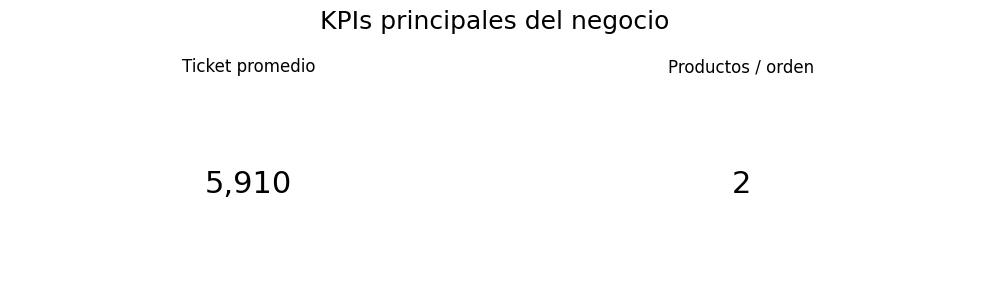

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

kpis = [
    ("Ticket promedio", prom_ticket),
    ("Productos / orden", cant_prom_producto_orden)
]

for ax, (nombre, valor) in zip(axes.flat, kpis):
    ax.text(
        0.5, 0.5,
        f"{valor:,.0f}",
        ha="center",
        va="center",
        fontsize=22
    )
    
    ax.set_title(nombre, fontsize=12)
    ax.axis("off")

plt.suptitle("KPIs principales del negocio", fontsize=18)
plt.tight_layout()
plt.show()

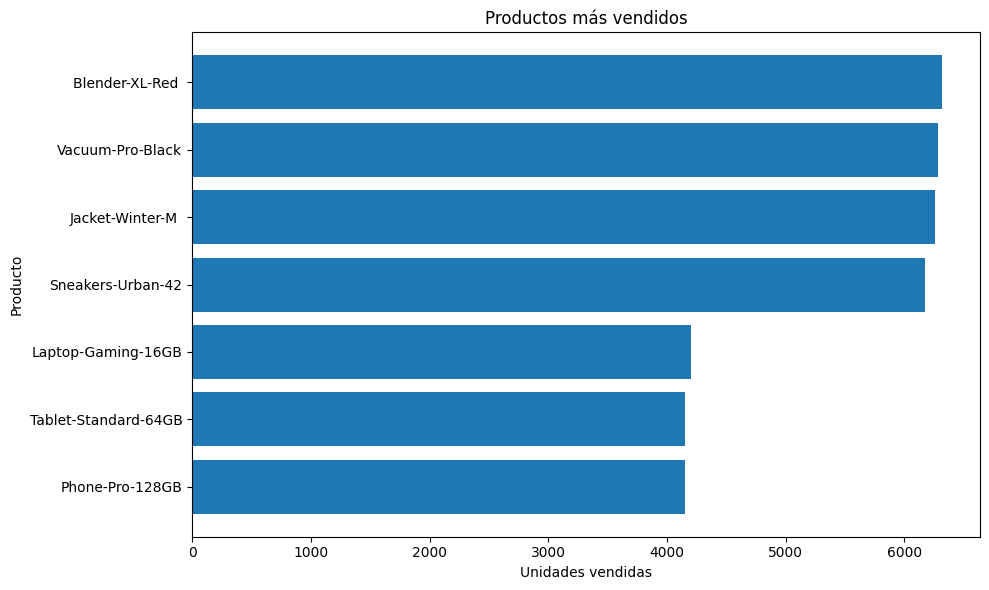

In [60]:
productos = pd.DataFrame({
    "producto": [
        "Blender-XL-Red ",
        "Vacuum-Pro-Black",
        "Jacket-Winter-M ",
        "Sneakers-Urban-42",
        "Laptop-Gaming-16GB",
        "Tablet-Standard-64GB",
        "Phone-Pro-128GB"
        
    ],
    "unidades": [6320,6284,6256,6172,4198,4153,4148]
})

productos = productos.sort_values(
    "unidades",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    productos["producto"],
    productos["unidades"]
)

plt.title("Productos más vendidos")
plt.xlabel("Unidades vendidas")
plt.ylabel("Producto")

plt.tight_layout()
plt.show()

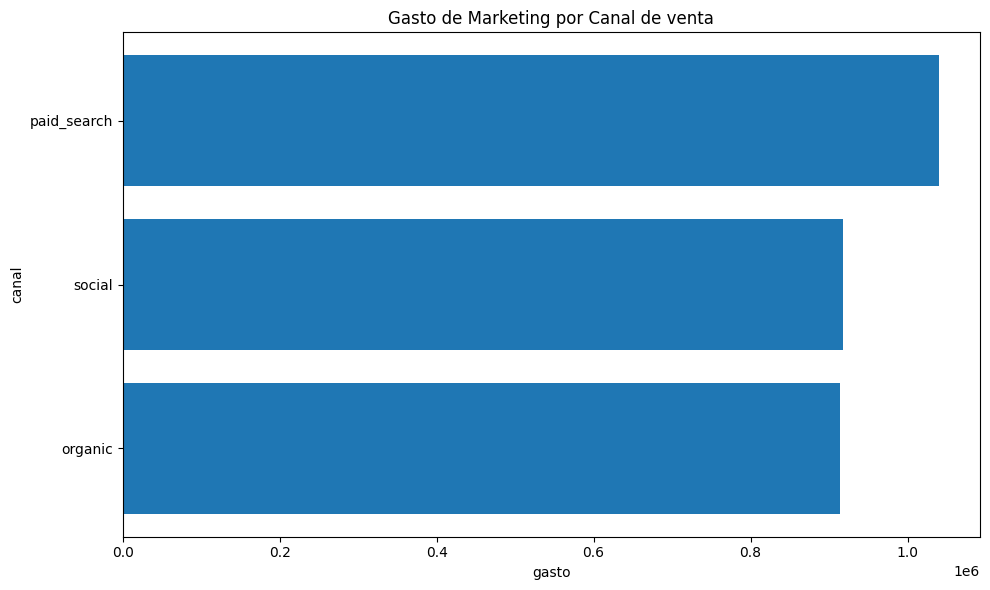

In [61]:
canales = pd.DataFrame({
    "canal": [
        "paid_search",
        "social",
        "organic"      
    ],
    "gasto": [1040267.31, 918043.21,913533.01]
})

canales = canales.sort_values(
    "gasto",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    canales["canal"],
    canales["gasto"]
)

plt.title("Gasto de Marketing por Canal de venta")
plt.xlabel("gasto")
plt.ylabel("canal")


plt.tight_layout()
plt.show()


**ANÁLISIS DEL COMPORTAMIENTO DEL NEGOCIO**

1. Rentabilidad del negocio

El análisis muestra que RappiPlus presenta un resultado rentable. El ingreso total generado por las ventas fue de 9.623.647, mientras que el gasto total de marketing alcanzó 2.871.843. Considerando los costos de los productos vendidos y la inversión en marketing, el negocio obtuvo un profit de 2.914.904.

Esto significa que, después de cubrir los costos asociados a la operación y la inversión en marketing, la empresa conserva un resultado positivo. Como referencia, el profit representa aproximadamente 30,3 % de los ingresos totales, lo que evidencia un margen favorable.

2. Comportamiento de las ventas

El ticket promedio por orden fue de $5.910, mientras que la cantidad promedio de productos por orden fue de 2 unidades. Esto indica que los clientes realizan compras relativamente pequeñas en términos de cantidad de productos, por lo que existe una oportunidad para incrementar el valor de cada pedido mediante estrategias de venta cruzada, promociones por volumen o paquetes de productos.

En cuanto al desempeño del portafolio, el producto con mayor cantidad de unidades vendidas fue Blender-XL-Red, con 6.324 unidades, seguido por Vacuum-Pro-Black, con 6.284, y Jacket-Winter-M, con 6.256. Por otro lado, Phone-Pro-128GB fue el producto con menor volumen de ventas, con 4.148 unidades.

3. Inversión en marketing

La inversión total en marketing fue de $2.871.843, distribuida entre tres canales.

Paid Search concentra la mayor inversión, aunque la distribución entre los tres canales es relativamente equilibrada.


## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [62]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'TU_USUARIO',
    'pwd': 'TU_CONTRASEÑA',
    'host': 'TU_HOST',
    'port': 5432,
    'db': 'TU_BASE_DE_DATOS'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [63]:

# Explorar tabla events
# vista general de la tabla
query_events = '''
SELECT *
FROM events
;
'''
events = pd.read_sql(query_events, con=engine)
events.head()


,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [64]:
# Explorar tabla events
# revisar nulos
query_events = '''

SELECT *
FROM events
WHERE categoria_producto IS NULL


'''
events = pd.read_sql(query_events, con=engine)
events

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto


In [93]:
# Explorar tabla events
# verificar etapas cuantos eventos hay 
query_events = '''
SELECT DISTINCT nombre_evento
FROM events;
;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,nombre_evento
0,add_payment_info
1,first_visit
2,begin_checkout
3,add_to_cart
4,select_item


In [94]:
# Explorar tabla events
# verificar cuantos momentos tiene cada usuario
query_events = '''

SELECT id_usuario,
count(timestamp_evento) AS conteo_marcatiempo
FROM events
GROUP BY id_usuario
HAVING count(timestamp_evento) > 5


'''
events = pd.read_sql(query_events, con=engine)
events

,id_usuario,conteo_marcatiempo
0,user_3160,14
1,user_5838,22
2,user_6035,11
3,user_1361,11
4,user_7849,12
...,...,...
7976,user_5752,18
7977,user_7298,17
7978,user_3286,13
7979,user_107,16


**observación**

Existen alto número de momentos de evento por usuario

**📊 Parte 1: Construcción del funnel**

In [96]:
# PARTE 1: Totales del funnel
# Usuarios únicos en cada etapa

query_totals = '''


SELECT nombre_evento,
COUNT(DISTINCT id_usuario) AS usuarios_unicos
FROM events
WHERE nombre_evento IN ('first_visit', 'add_to_cart','add_payment_info','purchase', 'select_item')
GROUP BY nombre_evento
ORDER BY usuarios_unicos DESC
;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,first_visit,7796
1,add_to_cart,7634
2,select_item,7582
3,add_payment_info,6250
4,purchase,6240


In [104]:
# PARTE 1: Totales del funnel
# armar el funnel

query_totals = '''


WITH cte_signup AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
),
cte_cart AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
),
cte_select_item AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
),
cte_payment_info AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
cte_purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
),

funnel AS (
    SELECT
        s.id_usuario,
        c.id_usuario AS cart,
        si.id_usuario AS select_item,
        pi.id_usuario AS payment_info,
        p.id_usuario AS purchase
    FROM cte_signup s
    LEFT JOIN cte_cart c
        ON s.id_usuario = c.id_usuario
    LEFT JOIN cte_select_item si
        ON c.id_usuario = si.id_usuario
    LEFT JOIN cte_payment_info pi
        ON si.id_usuario = pi.id_usuario
    LEFT JOIN cte_purchase p
        ON pi.id_usuario = p.id_usuario
)

SELECT
    COUNT(DISTINCT id_usuario) AS first_visit_users,
    COUNT(DISTINCT cart) AS add_to_cart_users,
    COUNT(DISTINCT select_item) AS select_item_users,
    COUNT(DISTINCT payment_info) AS add_payment_info_users,
    COUNT(DISTINCT purchase) AS purchase_users
FROM funnel;
  
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,first_visit_users,add_to_cart_users,select_item_users,add_payment_info_users,purchase_users
0,7796,7439,7052,5506,4276


**📉 Parte 2: Análisis de conversión**

In [106]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH cte_signup AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
),
cte_cart AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
),
cte_select_item AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
),
cte_payment_info AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
cte_purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
),

funnel AS (
    SELECT
        s.id_usuario,
        c.id_usuario AS cart,
        si.id_usuario AS select_item,
        pi.id_usuario AS payment_info,
        p.id_usuario AS purchase
    FROM cte_signup s
    LEFT JOIN cte_cart c
        ON s.id_usuario = c.id_usuario
    LEFT JOIN cte_select_item si
        ON c.id_usuario = si.id_usuario
    LEFT JOIN cte_payment_info pi
        ON si.id_usuario = pi.id_usuario
    LEFT JOIN cte_purchase p
        ON pi.id_usuario = p.id_usuario
),

funnel_counts AS (
    SELECT
        COUNT(DISTINCT id_usuario) AS first_visit_users,
        COUNT(DISTINCT cart) AS add_to_cart_users,
        COUNT(DISTINCT select_item) AS select_item_users,
        COUNT(DISTINCT payment_info) AS add_payment_info_users,
        COUNT(DISTINCT purchase) AS purchase_users
    FROM funnel
)

SELECT
    ROUND(add_to_cart_users * 100.0 / first_visit_users, 2)
        AS conversion_first_to_cart,

    ROUND(select_item_users * 100.0 / add_to_cart_users, 2)
        AS conversion_cart_to_select,

    ROUND(add_payment_info_users * 100.0 / select_item_users, 2)
        AS conversion_select_to_payment,

    ROUND(purchase_users * 100.0 / add_payment_info_users, 2)
        AS conversion_payment_to_purchase,

    ROUND(purchase_users * 100.0 / first_visit_users, 2)
        AS conversion_global

FROM funnel_counts;
  
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,conversion_first_to_cart,conversion_cart_to_select,conversion_select_to_payment,conversion_payment_to_purchase,conversion_global
0,95.42,94.8,78.08,77.66,54.85


**OBSERVACIÓN DEL EMBUDO DE CONVERSIÓN**

La construcción del funnel muestra que 7.796 usuarios iniciaron el proceso con first_visit, de los cuales 7.439 llegaron a add_to_cart, 7.052 a select_item, 5.506 a add_payment_info y finalmente 4.276 completaron una purchase. En cuanto al análisis de conversión, las tasas entre etapas fueron de 95,42%, 94,80%, 78,08% y 77,66%, respectivamente. La mayor pérdida de usuarios se presenta entre select_item y add_payment_info, donde se pierden 1.546 usuarios. Finalmente, la tasa de conversión global del funnel es de 54,85%, lo que significa que aproximadamente la mitad de los usuarios que iniciaron el proceso terminaron realizando una compra.


---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [69]:
# Explorar tabla users
# Revisión general
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(10)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free
3,user_3,2025-03-04,Mexico,desktop,free
4,user_4,2025-02-27,Argentina,desktop,free
5,user_5,2025-02-05,Colombia,desktop,free
6,user_6,2025-01-27,Mexico,mobile,free
7,user_7,2025-05-20,Colombia,mobile,free
8,user_8,2025-01-23,Mexico,mobile,free
9,user_9,2025-04-19,Colombia,desktop,free


In [70]:

# Explorar tabla users
# Revisión de nulos
query_users = '''
SELECT *
FROM users
WHERE tipo_plan IS NULL

'''
users = pd.read_sql(query_users, con=engine)
users


,id_usuario,fecha_registro,país,dispositivo,tipo_plan


In [71]:
# Explorar tabla users
# Revisión de nulos
query_users = '''
SELECT "fecha_registro",
CAST ("fecha_registro" AS DATE)
FROM users
;

'''
users = pd.read_sql(query_users, con=engine)
users


,fecha_registro,fecha_registro
0,2025-01-29,2025-01-29
1,2025-01-07,2025-01-07
2,2025-03-12,2025-03-12
3,2025-03-04,2025-03-04
4,2025-02-27,2025-02-27
...,...,...
7995,2025-05-16,2025-05-16
7996,2025-01-05,2025-01-05
7997,2025-04-19,2025-04-19
7998,2025-05-28,2025-05-28


**observación**

No hay nulos en las columnas de este dataset

In [72]:
# Explorar tabla users
# Revisión número de fechas de registro por usuarios
query_users = '''

SELECT id_usuario,
count(fecha_registro) AS conteo_registros
FROM users
GROUP BY id_usuario
HAVING count(fecha_registro) > 1

'''
users = pd.read_sql(query_users, con=engine)
users

,id_usuario,conteo_registros


**observación**

Se confirma que ningún cliente cuenta con mas de una fecha de registro

In [73]:
# Explorar tabla user_activity
# Revisión general
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(10)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1
3,user_0,2025-02-26,28,0
4,user_1,2025-01-14,7,0
5,user_1,2025-01-21,14,0
6,user_1,2025-01-28,21,1
7,user_1,2025-02-04,28,0
8,user_2,2025-03-19,7,0
9,user_2,2025-03-26,14,1


In [74]:
# Explorar tabla user_activity
# Revisión de nulos
query_user_activity = '''
SELECT *
FROM user_activity
WHERE activo IS NULL
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity 


,id_usuario,fecha_actividad,dias_despues_registro,activo


**observación**

No hay nulos en las columnas de este dataset

1. Se identifica la cohorte de cada usuario según el **mes de registro** y la **retención semanal**

In [75]:
#Unión de tablas users y user_activity
query_cohort_retention_final = '''

WITH tabla_1 AS (
    SELECT
        u.id_usuario,
        u.fecha_registro,
        u.país,
        u.dispositivo,
        u.tipo_plan,
        ua.fecha_actividad,
        ua.dias_despues_registro,
        ua.activo
    FROM users u
    LEFT JOIN user_activity ua
        ON u.id_usuario = ua.id_usuario
),
cohortes AS (
    SELECT
        id_usuario,
        DATE_TRUNC('month', MIN(fecha_registro::timestamp)) AS cohorte_mensual
    FROM tabla_1
    GROUP BY id_usuario
),
retencion AS (
    SELECT
        c.cohorte_mensual,
        COUNT(DISTINCT t.id_usuario) AS clientes_iniciales,
        COUNT(DISTINCT CASE WHEN t.dias_despues_registro >= 7  AND t.activo = 1 THEN t.id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN t.dias_despues_registro >= 14 AND t.activo = 1 THEN t.id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN t.dias_despues_registro >= 21 AND t.activo = 1 THEN t.id_usuario END) AS retenido_w3
    FROM cohortes c
    JOIN tabla_1 t
        ON c.id_usuario = t.id_usuario
    GROUP BY c.cohorte_mensual
)
SELECT*
FROM retencion
ORDER BY cohorte_mensual

'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte_mensual,clientes_iniciales,retenido_w1,retenido_w2,retenido_w3
0,2025-01-01,1627,1381,1253,1027
1,2025-02-01,1444,1255,1154,940
2,2025-03-01,1636,1428,1306,1060
3,2025-04-01,1606,1394,1261,1022
4,2025-05-01,1687,1446,1321,1088


2. Se calcula la **retención semanal**: cuántos usuarios se mantienen activos en cada semana desde su registro.

In [76]:
#Unión de tablas users y user_activity
query_cohort_retention_final = '''

WITH tabla_1 AS (
    SELECT
        u.id_usuario,
        u.fecha_registro,
        u.país,
        u.dispositivo,
        u.tipo_plan,
        ua.fecha_actividad,
        ua.dias_despues_registro,
        ua.activo
    FROM users u
    LEFT JOIN user_activity ua
        ON u.id_usuario = ua.id_usuario
),
cohortes AS (
    SELECT
        id_usuario,
        DATE_TRUNC('month', MIN(fecha_registro::timestamp)) AS cohorte_mensual
    FROM tabla_1
    GROUP BY id_usuario
),
retencion AS (
    SELECT
        c.cohorte_mensual,
        COUNT(DISTINCT t.id_usuario) AS clientes_iniciales,
        COUNT(DISTINCT CASE WHEN t.dias_despues_registro >= 7  AND t.activo = 1 THEN t.id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN t.dias_despues_registro >= 14 AND t.activo = 1 THEN t.id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN t.dias_despues_registro >= 21 AND t.activo = 1 THEN t.id_usuario END) AS retenido_w3
    FROM cohortes c
    JOIN tabla_1 t
        ON c.id_usuario = t.id_usuario
    GROUP BY c.cohorte_mensual
)
SELECT
    TO_CHAR(cohorte_mensual,'YYYY-MM') AS cohorte,
    clientes_iniciales,
    ROUND(retenido_w1::numeric / clientes_iniciales, 2) AS semana_1,
    ROUND(retenido_w2::numeric / clientes_iniciales, 2) AS semana_2,
    ROUND(retenido_w3::numeric / clientes_iniciales, 2) AS semana_3
FROM retencion
ORDER BY cohorte_mensual;


'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final



,cohorte,clientes_iniciales,semana_1,semana_2,semana_3
0,2025-01,1627,0.85,0.77,0.63
1,2025-02,1444,0.87,0.80,0.65
2,2025-03,1636,0.87,0.80,0.65
3,2025-04,1606,0.87,0.79,0.64
4,2025-05,1687,0.86,0.78,0.64


---

<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

La query está muy bien y estás obteniendo resultados adecuados pero lo complementarías mejor si agregaras una visualización.
</div>

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** No existe diferencia estadisticamente significativa en la tasa de conversión entre el experimento tratamiento y el control
   - **H₁ (Hipótesis alternativa):**  Existe diferencia estadisticamente significativa en la tasa de conversión entre el experimento tratamiento y el control
   
**Test estadístico:** Prueba Chi2 
**Nivel de significancia alpha:** 0.05

In [77]:

experiment = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

**Revisión general del dataset** 

In [78]:
revisar_datos(experiment,"experiment")

REVISIÓN: experiment

--- Primeras 5 filas ---


,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12



Dimensiones: 10000 filas x 7 columnas

--- Tipos de datos ---
id_usuario          object
variante            object
convirtio            int64
dispositivo         object
pais                object
duracion_sesion    float64
timestamp           object
dtype: object

--- Valores nulos ---
No hay valores nulos.

--- Filas duplicadas ---
0

--- Valores únicos por columna ---
id_usuario         10000
variante               2
convirtio              2
dispositivo            2
pais                   3
duracion_sesion     8446
timestamp            181
dtype: int64

--- Estadísticas descriptivas (numéricas) ---


,convirtio,duracion_sesion
count,10000.000000,10000.000000
mean,0.159900,159.862439
std,0.366532,81.074410
min,0.000000,20.010000
25%,0.000000,89.470000
50%,0.000000,159.725000
75%,0.000000,229.745000
max,1.000000,300.000000



--- Valores más frecuentes (categóricas) ---

id_usuario:
exp_user_9671    1
exp_user_8915    1
exp_user_8935    1
exp_user_6310    1
exp_user_3209    1
Name: id_usuario, dtype: int64

variante:
tratamiento    5035
control        4965
Name: variante, dtype: int64

dispositivo:
desktop    5042
mobile     4958
Name: dispositivo, dtype: int64

pais:
Mexico       3405
Argentina    3317
Colombia     3278
Name: pais, dtype: int64

timestamp:
2025-06-06    75
2025-01-23    75
2025-02-02    74
2025-05-01    72
2025-01-11    69
Name: timestamp, dtype: int64




**Aplicación del test estadístico: chi2** 

In [79]:
# Número de usuarios convertidos por variante (tratamiento, control)
Exitos_T = experiment[(experiment["convirtio"] == 1) & (experiment["variante"] == "tratamiento")]["convirtio"].count()
Exitos_C = experiment[(experiment["convirtio"] == 1) & (experiment["variante"] == "control")]["convirtio"].count()

# Total de usuarios por página
Total_T = experiment[experiment["variante"] == "tratamiento"]["id_usuario"].count()
Total_C = experiment[experiment["variante"] == "control"]["id_usuario"].count()
 

print(f"Usuarios convertidos en experimento - tratamiento:\n",Exitos_T,f"\nUsuarios convertidos en experimento - control:\n", Exitos_C)
print("-------------------------------------------------------------------------------")
print(f"Total usuarios convertidos en experimento - tratamiento:\n",Total_T,f"\nTotal Usuarios convertidos en experimento - control:\n", Total_C)

Usuarios convertidos en experimento - tratamiento:
 820 
Usuarios convertidos en experimento - control:
 779
-------------------------------------------------------------------------------
Total usuarios convertidos en experimento - tratamiento:
 5035 
Total Usuarios convertidos en experimento - control:
 4965


In [80]:
#Calculo de Tasa de conversión

Tasa_T = (Exitos_T/Total_T).round(3)
Tasa_C = (Exitos_C/Total_C).round(3)

print("Tasa conversion_T:",Tasa_T,"\nTasa conversion_C:" ,Tasa_C)

Tasa conversion_T: 0.163 
Tasa conversion_C: 0.157


In [81]:
#Creación de tabla cruzada

tabla=pd.crosstab(experiment["variante"],experiment["convirtio"])

tabla

convirtio,0,1
variante,,
control,4186,779
tratamiento,4215,820


In [82]:
# Aplicar prueba
chi2,p_value,dof,expected=chi2_contingency(tabla)

# Visualizar resultados
print(f"Estadístico : {chi2}")
print(f"Valor p: {p_value}")

Estadístico : 0.6177857659309294
Valor p: 0.43187130118526496


**Interpretación del resultado**  

Se identificó que no existe una diferencia estadísticamente significativa entre la tasa de conversión para las dos variantes existentes, que para este caso es la prueba tratamiento y la control. Aunque la Tasa de conversión, para la variante tratamiento fue de 16.3% y para el experimiento control de 15.7%

---